In [101]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import scipy
import yellowbrick
import mlxtend
print("Python:", sys.version)
print("All imports work. sklearn version:", sklearn.__version__)


Python: 3.14.0 (v3.14.0:ebf955df7a8, Oct  7 2025, 08:20:14) [Clang 16.0.0 (clang-1600.0.26.6)]
All imports work. sklearn version: 1.9.1


In [102]:
import pandas as pd

df = pd.read_csv("data/raw/mental-heath-in-tech-2016_20161114.csv")
df.shape

(1433, 63)

In [103]:
df.head()

,Are you self-employed?,How many employees does your company or organization have?,Is your employer primarily a tech company/organization?,Is your primary role within your company related to tech/IT?,Does your employer provide mental health benefits as part of healthcare coverage?,Do you know the options for mental health care available under your employer-provided coverage?,"Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?",Does your employer offer resources to learn more about mental health concerns and options for seeking help?,Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?,"If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",...,"If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?","If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?",What is your age?,What is your gender?,What country do you live in?,What US state or territory do you live in?,What country do you work in?,What US state or territory do you work in?,Which of the following best describes your work position?,Do you work remotely?
0,0,26-100,1.0,NaN,Not eligible for coverage / N/A,NaN,No,No,I don't know,Very easy,...,Not applicable to me,Not applicable to me,39,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Sometimes
1,0,6-25,1.0,NaN,No,Yes,Yes,Yes,Yes,Somewhat easy,...,Rarely,Sometimes,29,male,United States of America,Illinois,United States of America,Illinois,Back-end Developer|Front-end Developer,Never
2,0,6-25,1.0,NaN,No,NaN,No,No,I don't know,Neither easy nor difficult,...,Not applicable to me,Not applicable to me,38,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Always
3,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Sometimes,Sometimes,43,male,United Kingdom,NaN,United Kingdom,NaN,Supervisor/Team Lead,Sometimes
4,0,6-25,0.0,1.0,Yes,Yes,No,No,No,Neither easy nor difficult,...,Sometimes,Sometimes,43,Female,United States of America,Illinois,United States of America,Illinois,Executive Leadership|Supervisor/Team Lead|Dev ...,Sometimes


In [104]:
df.dtypes
df.dtypes.value_counts()

str        56
int64       4
float64     3
Name: count, dtype: int64

In [105]:
df.select_dtypes(include="number").columns

Index(['Are you self-employed?',
       'Is your employer primarily a tech company/organization?',
       'Is your primary role within your company related to tech/IT?',
       'Do you have medical coverage (private insurance or state-provided) which includes treatment of  mental health issues?',
       'Do you have previous employers?',
       'Have you ever sought treatment for a mental health issue from a mental health professional?',
       'What is your age?'],
      dtype='str')

In [106]:
num = df.select_dtypes(include="number")
print(num.nunique())
print(num.isna().sum())

Are you self-employed?                                                                                                    2
Is your employer primarily a tech company/organization?                                                                   2
Is your primary role within your company related to tech/IT?                                                              2
Do you have medical coverage (private insurance or state-provided) which includes treatment of  mental health issues?     2
Do you have previous employers?                                                                                           2
Have you ever sought treatment for a mental health issue from a mental health professional?                               2
What is your age?                                                                                                        53
dtype: int64
Are you self-employed?                                                                                                 

In [107]:
selfemp = num["Are you self-employed?"]
employer_tech = num["Is your employer primarily a tech company/organization?"]
coverage = num.iloc[:, 3]

print(pd.crosstab(selfemp, employer_tech.fillna(-1)))
print(pd.crosstab(selfemp, coverage.fillna(-1)))

Is your employer primarily a tech company/organization?  -1.0   0.0   1.0
Are you self-employed?                                                   
0                                                           0   263   883
1                                                         287     0     0
Do you have medical coverage (private insurance or state-provided) which includes treatment of  mental health issues?  -1.0  \
Are you self-employed?                                                                                                        
0                                                                                                                      1146   
1                                                                                                                         0   

Do you have medical coverage (private insurance or state-provided) which includes treatment of  mental health issues?   0.0  \
Are you self-employed?                                              

In [108]:
role_tech = num.iloc[:, 2]

print(pd.crosstab(employer_tech.fillna(-1), role_tech.fillna(-1)))

Is your primary role within your company related to tech/IT?  -1.0   0.0   1.0
Is your employer primarily a tech company/organ...                            
-1.0                                                           287     0     0
 0.0                                                             0    15   248
 1.0                                                           883     0     0


In [109]:
for i, col in enumerate(df.columns):
    print(i, col)

0 Are you self-employed?
1 How many employees does your company or organization have?
2 Is your employer primarily a tech company/organization?
3 Is your primary role within your company related to tech/IT?
4 Does your employer provide mental health benefits as part of healthcare coverage?
5 Do you know the options for mental health care available under your employer-provided coverage?
6 Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?
7 Does your employer offer resources to learn more about mental health concerns and options for seeking help?
8 Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?
9 If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:
10 Do you think that discussing a mental health disorder with your employer would have negative consequences?

In [110]:
original_columns = list(df.columns)
print(len(original_columns))

names_0_17 = [
    "self_employed",
    "company_size",
    "employer_is_tech",
    "role_is_tech",
    "cur_benefits_provided",
    "cur_knows_care_options",
    "cur_employer_discussed_mh",
    "cur_resources_offered",
    "cur_anonymity_protected",
    "cur_leave_ease",
    "cur_mh_disclosure_conseq",
    "cur_ph_disclosure_conseq",
    "cur_comfort_coworkers",
    "cur_comfort_supervisor",
    "cur_mh_equals_ph",
    "cur_observed_neg_conseq",
    "mh_coverage_self_emp",
    "knows_help_resources_self_emp",
]

print(len(names_0_17))
for i in range(18):
    print(i, names_0_17[i], "<-", original_columns[i][:60])

names_18_35 = [
    "reveal_to_clients_self_emp",
    "reveal_clients_neg_impact_self_emp",
    "reveal_to_coworkers_self_emp",
    "reveal_coworkers_neg_impact_self_emp",
    "productivity_affected_self_emp",
    "productivity_pct_affected_self_emp",
    "has_prev_employers",
    "prev_benefits_provided",
    "prev_knew_care_options",
    "prev_employer_discussed_mh",
    "prev_resources_offered",
    "prev_anonymity_protected",
    "prev_mh_disclosure_conseq",
    "prev_ph_disclosure_conseq",
    "prev_willing_coworkers",
    "prev_willing_supervisor",
    "prev_mh_equals_ph",
    "prev_observed_neg_conseq",
]

print(len(names_18_35))
for i in range(18):
    print(i + 18, names_18_35[i], "<-", original_columns[i + 18][:60])

names_36_62 = [
    "would_raise_ph_interview",
    "why_ph_interview_text",
    "would_raise_mh_interview",
    "why_mh_interview_text",
    "career_hurt_if_identified",
    "coworkers_view_negatively",
    "willing_share_friends_family",
    "observed_unsupportive_response",
    "observation_less_likely_reveal",
    "family_history_mh",
    "mh_disorder_past",
    "mh_disorder_current",
    "current_conditions_list",
    "suspected_conditions_list",
    "diagnosed_by_professional",
    "diagnosed_conditions_list",
    "sought_treatment",
    "interferes_when_treated",
    "interferes_when_not_treated",
    "age",
    "gender",
    "country_live",
    "us_state_live",
    "country_work",
    "us_state_work",
    "work_position",
    "works_remotely",
]

print(len(names_36_62))
for i in range(27):
    print(i + 36, names_36_62[i], "<-", original_columns[i + 36][:60])

new_names = names_0_17 + names_18_35 + names_36_62

df.columns = new_names

print(df.shape)
print(list(df.columns[:5]))


63
18
0 self_employed <- Are you self-employed?
1 company_size <- How many employees does your company or organization have?
2 employer_is_tech <- Is your employer primarily a tech company/organization?
3 role_is_tech <- Is your primary role within your company related to tech/IT?
4 cur_benefits_provided <- Does your employer provide mental health benefits as part of
5 cur_knows_care_options <- Do you know the options for mental health care available und
6 cur_employer_discussed_mh <- Has your employer ever formally discussed mental health (for
7 cur_resources_offered <- Does your employer offer resources to learn more about menta
8 cur_anonymity_protected <- Is your anonymity protected if you choose to take advantage 
9 cur_leave_ease <- If a mental health issue prompted you to request a medical l
10 cur_mh_disclosure_conseq <- Do you think that discussing a mental health disorder with y
11 cur_ph_disclosure_conseq <- Do you think that discussing a physical health issue with yo
12 cur

In [111]:
column_map = pd.DataFrame({
    "position": range(len(new_names)),
    "short_name": new_names,
    "original_question": original_columns,
})

print(column_map.shape)
column_map.head()

column_map.to_csv("data/column_map.csv", index=False)

check = pd.read_csv("data/column_map.csv")

(63, 3)


In [112]:
for col in ["company_size", "cur_benefits_provided", "cur_leave_ease"]:
    print(col)
    print(df[col].value_counts(dropna=False))
    print()

company_size
company_size
26-100            292
NaN               287
More than 1000    256
100-500           248
6-25              210
500-1000           80
1-5                60
Name: count, dtype: int64

cur_benefits_provided
cur_benefits_provided
Yes                                531
I don't know                       319
NaN                                287
No                                 213
Not eligible for coverage / N/A     83
Name: count, dtype: int64

cur_leave_ease
cur_leave_ease
NaN                           287
Somewhat easy                 281
Very easy                     220
Somewhat difficult            199
Neither easy nor difficult    178
I don't know                  150
Very difficult                118
Name: count, dtype: int64



In [113]:
scale_levels = {
    "self_employed": "binary",
    "company_size": "ordinal",
    "employer_is_tech": "binary",
    "role_is_tech": "binary",
    "cur_benefits_provided": "nominal",
    "cur_leave_ease": "ordinal",
}

print(len(scale_levels))
print(scale_levels["cur_leave_ease"])

6
ordinal


In [114]:
for col in ["cur_knows_care_options", "cur_employer_discussed_mh",
            "cur_resources_offered", "cur_anonymity_protected"]:
    print(col)
    print(df[col].value_counts(dropna=False))
    print()

cur_knows_care_options
cur_knows_care_options
NaN              420
No               354
I am not sure    352
Yes              307
Name: count, dtype: int64

cur_employer_discussed_mh
cur_employer_discussed_mh
No              813
NaN             287
Yes             230
I don't know    103
Name: count, dtype: int64

cur_resources_offered
cur_resources_offered
No              531
I don't know    320
Yes             295
NaN             287
Name: count, dtype: int64

cur_anonymity_protected
cur_anonymity_protected
I don't know    742
Yes             320
NaN             287
No               84
Name: count, dtype: int64



In [115]:
scale_levels.update({
    "cur_knows_care_options": "nominal",
    "cur_employer_discussed_mh": "nominal",
    "cur_resources_offered": "nominal",
    "cur_anonymity_protected": "nominal",
})

print(len(scale_levels))

10


In [116]:
for col in ["cur_mh_disclosure_conseq", "cur_ph_disclosure_conseq",
            "cur_comfort_coworkers", "cur_comfort_supervisor"]:
    print(col)
    print(df[col].value_counts(dropna=False))
    print()

cur_mh_disclosure_conseq
cur_mh_disclosure_conseq
Maybe    487
No       438
NaN      287
Yes      221
Name: count, dtype: int64

cur_ph_disclosure_conseq
cur_ph_disclosure_conseq
No       837
NaN      287
Maybe    268
Yes       41
Name: count, dtype: int64

cur_comfort_coworkers
cur_comfort_coworkers
Maybe    479
No       392
NaN      287
Yes      275
Name: count, dtype: int64

cur_comfort_supervisor
cur_comfort_supervisor
Yes      428
Maybe    382
No       336
NaN      287
Name: count, dtype: int64



In [117]:
scale_levels.update({
    "cur_mh_disclosure_conseq": "ordinal",
    "cur_ph_disclosure_conseq": "ordinal",
    "cur_comfort_coworkers": "ordinal",
    "cur_comfort_supervisor": "ordinal",
})

print(len(scale_levels))

14


In [118]:
for col in ["cur_mh_equals_ph", "cur_observed_neg_conseq", "knows_help_resources_self_emp"]:
    print(col)
    print(df[col].value_counts(dropna=False))
    print()


cur_mh_equals_ph
cur_mh_equals_ph
I don't know    493
Yes             350
No              303
NaN             287
Name: count, dtype: int64

cur_observed_neg_conseq
cur_observed_neg_conseq
No     1048
NaN     287
Yes      98
Name: count, dtype: int64

knows_help_resources_self_emp
knows_help_resources_self_emp
NaN                     1146
I know some              141
Yes, I know several       83
No, I don't know any      63
Name: count, dtype: int64



In [119]:
scale_levels.update({
    "cur_mh_equals_ph": "nominal",
    "cur_observed_neg_conseq": "binary",
    "mh_coverage_self_emp": "binary",
    "knows_help_resources_self_emp": "ordinal",
})

print(len(scale_levels))


18


In [120]:
print(pd.crosstab(df["self_employed"], df["knows_help_resources_self_emp"].fillna("missing")))

knows_help_resources_self_emp  I know some  No, I don't know any  \
self_employed                                                      
0                                        0                     0   
1                                      141                    63   

knows_help_resources_self_emp  Yes, I know several  missing  
self_employed                                                
0                                                0     1146  
1                                               83        0  


In [121]:
for col in ["reveal_to_clients_self_emp", "reveal_clients_neg_impact_self_emp",
            "reveal_to_coworkers_self_emp", "reveal_coworkers_neg_impact_self_emp"]:
    print(col)
    print(df[col].value_counts(dropna=False))
    print()

reveal_to_clients_self_emp
reveal_to_clients_self_emp
NaN                                          1146
Not applicable to me                          101
No, because it would impact me negatively      83
Sometimes, if it comes up                      57
No, because it doesn't matter                  44
Yes, always                                     2
Name: count, dtype: int64

reveal_clients_neg_impact_self_emp
reveal_clients_neg_impact_self_emp
NaN             1289
I'm not sure      66
No                42
Yes               36
Name: count, dtype: int64

reveal_to_coworkers_self_emp
reveal_to_coworkers_self_emp
NaN                                          1146
Not applicable to me                          111
Sometimes, if it comes up                      99
No, because it would impact me negatively      51
No, because it doesn't matter                  15
Yes, always                                    11
Name: count, dtype: int64

reveal_coworkers_neg_impact_self_emp
reveal_coworkers

In [122]:
for col in ["reveal_to_clients_self_emp", "reveal_clients_neg_impact_self_emp",
            "reveal_to_coworkers_self_emp", "reveal_coworkers_neg_impact_self_emp"]:
    print(col)
    print(pd.crosstab(df["self_employed"], df[col].isna()))
    print()

reveal_to_clients_self_emp
reveal_to_clients_self_emp  False  True 
self_employed                           
0                               0   1146
1                             287      0

reveal_clients_neg_impact_self_emp
reveal_clients_neg_impact_self_emp  False  True 
self_employed                                   
0                                       0   1146
1                                     144    143

reveal_to_coworkers_self_emp
reveal_to_coworkers_self_emp  False  True 
self_employed                             
0                                 0   1146
1                               287      0

reveal_coworkers_neg_impact_self_emp
reveal_coworkers_neg_impact_self_emp  False  True 
self_employed                                     
0                                         0   1146
1                                       287      0



In [123]:
a = df["reveal_to_clients_self_emp"].fillna("missing").str[:20]
b = df["reveal_clients_neg_impact_self_emp"].fillna("missing").str[:20]
print(pd.crosstab(a, b))

reveal_clients_neg_impact_self_emp  I'm not sure  No  Yes  missing
reveal_to_clients_self_emp                                        
No, because it doesn                          13   7    3       21
No, because it would                          23   5   24       31
Not applicable to me                           6   4    1       90
Sometimes, if it com                          24  24    8        1
Yes, always                                    0   2    0        0
missing                                        0   0    0     1146


In [124]:
scale_levels.update({
    "reveal_to_clients_self_emp": "nominal",
    "reveal_clients_neg_impact_self_emp": "nominal",
    "reveal_to_coworkers_self_emp": "nominal",
    "reveal_coworkers_neg_impact_self_emp": "nominal",
})

print(len(scale_levels))
print(set(scale_levels) - set(df.columns))
print(list(df.columns[18:22]))
print(list(column_map.loc[18:21, "short_name"]))

22
set()
['reveal_to_clients_self_emp', 'reveal_clients_neg_impact_self_emp', 'reveal_to_coworkers_self_emp', 'reveal_coworkers_neg_impact_self_emp']
['reveal_to_clients_self_emp', 'reveal_clients_neg_impact_self_emp', 'reveal_to_coworkers_self_emp', 'reveal_coworkers_neg_impact_self_emp']


In [125]:
for col in ["productivity_affected_self_emp", "productivity_pct_affected_self_emp"]:
    print(col)
    print(df[col].value_counts(dropna=False))
    print()
    

productivity_affected_self_emp
productivity_affected_self_emp
NaN                     1146
Yes                      204
Unsure                    38
Not applicable to me      31
No                        14
Name: count, dtype: int64

productivity_pct_affected_self_emp
productivity_pct_affected_self_emp
NaN        1229
1-25%        92
26-50%       72
51-75%       26
76-100%      14
Name: count, dtype: int64



In [126]:
print(pd.crosstab(df["self_employed"], df["productivity_affected_self_emp"].isna()))
print()
pct_asked = df["productivity_pct_affected_self_emp"].notna()
print(pd.crosstab(df["productivity_affected_self_emp"].fillna("missing"), pct_asked))

productivity_affected_self_emp  False  True 
self_employed                               
0                                   0   1146
1                                 287      0

productivity_pct_affected_self_emp  False  True 
productivity_affected_self_emp                  
No                                     14      0
Not applicable to me                   31      0
Unsure                                 38      0
Yes                                     0    204
missing                              1146      0


In [127]:
scale_levels.update({
    "productivity_affected_self_emp": "nominal",
    "productivity_pct_affected_self_emp": "ordinal",
})

print(len(scale_levels))
print(set(scale_levels) - set(df.columns))

24
set()


In [128]:
print(df["has_prev_employers"].value_counts())

prev_cols = [c for c in df.columns if c.startswith("prev_")]
print(len(prev_cols))

print(df[prev_cols].isna().sum())


has_prev_employers
1    1264
0     169
Name: count, dtype: int64
11
prev_benefits_provided        169
prev_knew_care_options        169
prev_employer_discussed_mh    169
prev_resources_offered        169
prev_anonymity_protected      169
prev_mh_disclosure_conseq     169
prev_ph_disclosure_conseq     169
prev_willing_coworkers        169
prev_willing_supervisor       169
prev_mh_equals_ph             169
prev_observed_neg_conseq      169
dtype: int64


In [129]:
answered = df[prev_cols].notna().sum(axis=1)
print(pd.crosstab(df["has_prev_employers"], answered))


col_0                0     11
has_prev_employers           
0                   169     0
1                     0  1264


In [130]:
for col in ["prev_benefits_provided", "prev_knew_care_options",
            "prev_employer_discussed_mh", "prev_resources_offered"]:
    print(col)
    print(df[col].value_counts(dropna=False))
    print()

prev_benefits_provided
prev_benefits_provided
Some did             391
No, none did         372
I don't know         313
Yes, they all did    188
NaN                  169
Name: count, dtype: int64

prev_knew_care_options
prev_knew_care_options
N/A (not currently aware)          582
I was aware of some                384
Yes, I was aware of all of them    181
NaN                                169
No, I only became aware later      117
Name: count, dtype: int64

prev_employer_discussed_mh
prev_employer_discussed_mh
None did             890
Some did             255
NaN                  169
I don't know          86
Yes, they all did     33
Name: count, dtype: int64

prev_resources_offered
prev_resources_offered
None did             842
Some did             371
NaN                  169
Yes, they all did     51
Name: count, dtype: int64



In [131]:
scale_levels.update({
    "has_prev_employers": "binary",
    "prev_benefits_provided": "ordinal",
    "prev_knew_care_options": "nominal",
    "prev_employer_discussed_mh": "ordinal",
    "prev_resources_offered": "ordinal",
})

print(len(scale_levels))
print(set(scale_levels) - set(df.columns))

29
set()


In [132]:
for col in ["prev_anonymity_protected", "prev_mh_disclosure_conseq",
            "prev_ph_disclosure_conseq", "prev_willing_coworkers"]:
    print(col)
    print(df[col].value_counts(dropna=False))
    print()
    

prev_anonymity_protected
prev_anonymity_protected
I don't know    860
NaN             169
Yes, always     164
No              121
Sometimes       119
Name: count, dtype: int64

prev_mh_disclosure_conseq
prev_mh_disclosure_conseq
Some of them        615
I don't know        310
Yes, all of them    226
NaN                 169
None of them        113
Name: count, dtype: int64

prev_ph_disclosure_conseq
prev_ph_disclosure_conseq
Some of them        631
None of them        559
NaN                 169
Yes, all of them     74
Name: count, dtype: int64

prev_willing_coworkers
prev_willing_coworkers
Some of my previous employers           740
No, at none of my previous employers    430
NaN                                     169
Yes, at all of my previous employers     94
Name: count, dtype: int64



In [133]:
scale_levels.update({
    "prev_anonymity_protected": "nominal",
    "prev_mh_disclosure_conseq": "ordinal",
    "prev_ph_disclosure_conseq": "ordinal",
    "prev_willing_coworkers": "ordinal",
})

print(len(scale_levels))
print(set(scale_levels) - set(df.columns))

33
set()


In [134]:
for col in ["prev_willing_supervisor", "prev_mh_equals_ph", "prev_observed_neg_conseq"]:
    print(col)
    print(df[col].value_counts(dropna=False))
    print()

prev_willing_supervisor
prev_willing_supervisor
Some of my previous employers           654
No, at none of my previous employers    416
NaN                                     169
I don't know                            101
Yes, at all of my previous employers     93
Name: count, dtype: int64

prev_mh_equals_ph
prev_mh_equals_ph
None did             463
Some did             427
I don't know         331
NaN                  169
Yes, they all did     43
Name: count, dtype: int64

prev_observed_neg_conseq
prev_observed_neg_conseq
None of them        758
Some of them        444
NaN                 169
Yes, all of them     62
Name: count, dtype: int64



In [135]:
scale_levels.update({
    "prev_willing_supervisor": "ordinal",
    "prev_mh_equals_ph": "ordinal",
    "prev_observed_neg_conseq": "ordinal",
})

print(len(scale_levels))
print(set(scale_levels) - set(df.columns))

36
set()


In [136]:
print(len(scale_levels))
print(set(scale_levels) - set(df.columns))
print(list(df.columns[22:24]))
print(list(column_map.loc[22:23, "short_name"]))

36
set()
['productivity_affected_self_emp', 'productivity_pct_affected_self_emp']
['productivity_affected_self_emp', 'productivity_pct_affected_self_emp']


In [137]:
for col in ["would_raise_ph_interview", "would_raise_mh_interview",
            "career_hurt_if_identified", "coworkers_view_negatively"]:
    print(col)
    print(df[col].value_counts(dropna=False))
    print()

would_raise_ph_interview
would_raise_ph_interview
Maybe    633
No       441
Yes      359
Name: count, dtype: int64

would_raise_mh_interview
would_raise_mh_interview
No       883
Maybe    438
Yes      112
Name: count, dtype: int64

career_hurt_if_identified
career_hurt_if_identified
Maybe                         588
Yes, I think it would         563
No, I don't think it would    147
Yes, it has                   105
No, it has not                 30
Name: count, dtype: int64

coworkers_view_negatively
coworkers_view_negatively
Maybe                           591
Yes, I think they would         403
No, I don't think they would    348
No, they do not                  49
Yes, they do                     42
Name: count, dtype: int64



In [138]:
scale_levels.update({
    "would_raise_ph_interview": "ordinal",
    "would_raise_mh_interview": "ordinal",
    "career_hurt_if_identified": "ordinal",
    "coworkers_view_negatively": "ordinal",
})

print(len(scale_levels))
print(set(scale_levels) - set(df.columns))

40
set()


In [139]:
for col in ["willing_share_friends_family", "observed_unsupportive_response",
            "observation_less_likely_reveal", "family_history_mh"]:
    print(col)
    print(df[col].value_counts(dropna=False))
    print()

willing_share_friends_family
willing_share_friends_family
Somewhat open                                            640
Very open                                                251
Somewhat not open                                        214
Neutral                                                  141
Not applicable to me (I do not have a mental illness)    112
Not open at all                                           75
Name: count, dtype: int64

observed_unsupportive_response
observed_unsupportive_response
No                    567
Maybe/Not sure        346
Yes, I observed       264
Yes, I experienced    167
NaN                    89
Name: count, dtype: int64

observation_less_likely_reveal
observation_less_likely_reveal
NaN      776
Yes      246
No       234
Maybe    177
Name: count, dtype: int64

family_history_mh
family_history_mh
Yes             670
No              488
I don't know    275
Name: count, dtype: int64



In [140]:
scale_levels.update({
    "willing_share_friends_family": "ordinal",
    "observed_unsupportive_response": "nominal",
    "observation_less_likely_reveal": "ordinal",
    "family_history_mh": "nominal",
})

print(len(scale_levels))
print(set(scale_levels) - set(df.columns))

44
set()


In [141]:
miss = df["observed_unsupportive_response"].isna()
print(pd.crosstab([df["self_employed"], df["has_prev_employers"]], miss))
print()
print(pd.crosstab(df["observed_unsupportive_response"].fillna("missing"),
                  df["observation_less_likely_reveal"].fillna("missing")))

observed_unsupportive_response    False  True 
self_employed has_prev_employers              
0             0                     118     13
              1                     976     39
1             0                      24     14
              1                     226     23

observation_less_likely_reveal  Maybe   No  Yes  missing
observed_unsupportive_response                          
Maybe/Not sure                     82  137   53       74
No                                  0    0    0      567
Yes, I experienced                 33   41   65       28
Yes, I observed                    62   56  128       18
missing                             0    0    0       89


In [142]:
for col in ["mh_disorder_past", "mh_disorder_current", "diagnosed_by_professional"]:
    print(col)
    print(df[col].value_counts(dropna=False))
    print()

mh_disorder_past
mh_disorder_past
Yes      736
No       451
Maybe    246
Name: count, dtype: int64

mh_disorder_current
mh_disorder_current
Yes      575
No       531
Maybe    327
Name: count, dtype: int64

diagnosed_by_professional
diagnosed_by_professional
No     717
Yes    716
Name: count, dtype: int64



In [143]:
scale_levels.update({
    "mh_disorder_past": "ordinal",
    "mh_disorder_current": "ordinal",
    "diagnosed_by_professional": "binary",
})

print(len(scale_levels))
print(set(scale_levels) - set(df.columns))

47
set()


In [144]:
for col in ["interferes_when_treated", "interferes_when_not_treated"]:
    print(col)
    print(df[col].value_counts(dropna=False))
    print()

print(pd.crosstab(df["interferes_when_treated"].isna(),
                  df["interferes_when_not_treated"].isna()))

interferes_when_treated
interferes_when_treated
Not applicable to me    557
Sometimes               369
Rarely                  322
Never                   120
Often                    65
Name: count, dtype: int64

interferes_when_not_treated
interferes_when_not_treated
Often                   538
Not applicable to me    468
Sometimes               363
Rarely                   52
Never                    12
Name: count, dtype: int64

interferes_when_not_treated  False
interferes_when_treated           
False                         1433


In [145]:
scale_levels.update({
    "sought_treatment": "binary",
    "interferes_when_treated": "ordinal",
    "interferes_when_not_treated": "ordinal",
})

print(len(scale_levels))
print(set(scale_levels) - set(df.columns))

50
set()


In [146]:
for col in ["country_live", "us_state_live", "country_work",
            "us_state_work", "work_position", "works_remotely"]:
    print(col, "| distinct:", df[col].nunique(), "| missing:", df[col].isna().sum())
    print(df[col].value_counts().head(5))
    print()

country_live | distinct: 53 | missing: 0
country_live
United States of America    840
United Kingdom              180
Canada                       78
Germany                      58
Netherlands                  48
Name: count, dtype: int64

us_state_live | distinct: 47 | missing: 593
us_state_live
California    130
Illinois       56
Michigan       48
New York       45
Washington     43
Name: count, dtype: int64

country_work | distinct: 53 | missing: 0
country_work
United States of America    851
United Kingdom              183
Canada                       74
Germany                      58
Netherlands                  47
Name: count, dtype: int64

us_state_work | distinct: 48 | missing: 582
us_state_work
California    141
Illinois       58
New York       49
Michigan       47
Texas          44
Name: count, dtype: int64

work_position | distinct: 264 | missing: 0
work_position
Back-end Developer                        263
Front-end Developer                       125
Other              

In [147]:
us_live = df["country_live"] == "United States of America"
print(pd.crosstab(us_live, df["us_state_live"].isna()))

us_state_live  False  True 
country_live               
False              0    593
True             840      0


In [148]:
 print(df["works_remotely"].value_counts(dropna=False))

works_remotely
Sometimes    757
Always       343
Never        333
Name: count, dtype: int64


In [149]:
for col in ["us_state_work", "work_position"]:
    print(col, "| distinct:", df[col].nunique(), "| missing:", df[col].isna().sum())
    print(df[col].value_counts().head(5))
    print()

us_state_work | distinct: 48 | missing: 582
us_state_work
California    141
Illinois       58
New York       49
Michigan       47
Texas          44
Name: count, dtype: int64

work_position | distinct: 264 | missing: 0
work_position
Back-end Developer                        263
Front-end Developer                       125
Other                                     112
Supervisor/Team Lead                       68
Back-end Developer|Front-end Developer     61
Name: count, dtype: int64



In [150]:
us_work = df["country_work"] == "United States of America"
print(pd.crosstab(us_work, df["us_state_work"].isna()))

us_state_work  False  True 
country_work               
False              0    582
True             851      0


In [151]:
print("work_position | distinct:", df["work_position"].nunique(),
      "| missing:", df["work_position"].isna().sum())
print(df["work_position"].value_counts().head(5))

work_position | distinct: 264 | missing: 0
work_position
Back-end Developer                        263
Front-end Developer                       125
Other                                     112
Supervisor/Team Lead                       68
Back-end Developer|Front-end Developer     61
Name: count, dtype: int64


In [152]:
scale_levels.update({
    "country_live": "nominal",
    "us_state_live": "nominal",
    "country_work": "nominal",
    "us_state_work": "nominal",
    "works_remotely": "ordinal",
    "age": "ratio",
    "why_ph_interview_text": "free text",
    "why_mh_interview_text": "free text",
    "current_conditions_list": "nominal",
    "suspected_conditions_list": "nominal",
    "diagnosed_conditions_list": "nominal",
    "gender": "free text",
})

print(len(scale_levels))
print(set(scale_levels) - set(df.columns))
print(set(df.columns) - set(scale_levels))

62
set()
{'work_position'}


In [153]:
scale_levels["work_position"] = "nominal"

print(len(scale_levels))
print(set(df.columns) - set(scale_levels))

roles = df["work_position"].str.split("|").explode()
print("distinct single roles:", roles.nunique())
print(roles.value_counts().head(8))
print(df["work_position"].str.count(r"\|").add(1).value_counts().sort_index())

63
set()
distinct single roles: 12
work_position
Back-end Developer      737
Front-end Developer     502
DevOps/SysAdmin         282
Supervisor/Team Lead    277
Other                   187
Support                 168
One-person shop         161
Designer                135
Name: count, dtype: int64
work_position
1     817
2     281
3     159
4     106
5      33
6      22
7       9
8       3
9       2
10      1
Name: count, dtype: int64


In [154]:
column_map["scale_level"] = column_map["short_name"].map(scale_levels)

print(column_map["scale_level"].isna().sum())
print(column_map["scale_level"].value_counts())
column_map.head(8)

0
scale_level
ordinal      28
nominal      23
binary        8
free text     3
ratio         1
Name: count, dtype: int64


,position,short_name,original_question,scale_level
0,0,self_employed,Are you self-employed?,binary
1,1,company_size,How many employees does your company or organi...,ordinal
2,2,employer_is_tech,Is your employer primarily a tech company/orga...,binary
3,3,role_is_tech,Is your primary role within your company relat...,binary
4,4,cur_benefits_provided,Does your employer provide mental health benef...,nominal
5,5,cur_knows_care_options,Do you know the options for mental health care...,nominal
6,6,cur_employer_discussed_mh,Has your employer ever formally discussed ment...,nominal
7,7,cur_resources_offered,Does your employer offer resources to learn mo...,nominal


In [155]:
group_positions = {
    "work_setting": [0, 1, 2, 3, 24, 61, 62],
    "workplace": list(range(4, 16)) + list(range(25, 36)),
    "attitudes": list(range(18, 22)) + list(range(36, 45)),
    "personal": [16, 17, 22, 23] + list(range(45, 55)),
    "demographic": list(range(55, 61)),
}

all_positions = []
for positions in group_positions.values():
    all_positions = all_positions + positions

print(len(all_positions), len(set(all_positions)))
assert sorted(all_positions) == list(range(63)), "a position is missing or used twice"

column_map["group"] = ""
for tag, positions in group_positions.items():
    column_map.loc[positions, "group"] = tag

print(column_map["group"].value_counts())

63 63
group
workplace       23
personal        14
attitudes       13
work_setting     7
demographic      6
Name: count, dtype: int64


In [156]:
selfemp = df["self_employed"] == 1

for col in df.columns[[1, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]]:
    print(col, (df[col].isna() == selfemp).all(), df[col].isna().sum())

print()
print(df.iloc[:, [37, 39, 48, 49, 51, 56]].isna().sum())

company_size True 287
cur_benefits_provided True 287
cur_knows_care_options False 420
cur_employer_discussed_mh True 287
cur_resources_offered True 287
cur_anonymity_protected True 287
cur_leave_ease True 287
cur_mh_disclosure_conseq True 287
cur_ph_disclosure_conseq True 287
cur_comfort_coworkers True 287
cur_comfort_supervisor True 287
cur_mh_equals_ph True 287
cur_observed_neg_conseq True 287

why_ph_interview_text         338
why_mh_interview_text         307
current_conditions_list       865
suspected_conditions_list    1111
diagnosed_conditions_list     722
gender                          3
dtype: int64


In [157]:
print(pd.crosstab(df["mh_disorder_current"], df["current_conditions_list"].notna()))
print()
print(pd.crosstab(df["mh_disorder_current"], df["suspected_conditions_list"].notna()))
print()
print(pd.crosstab(df["diagnosed_by_professional"], df["diagnosed_conditions_list"].notna()))

current_conditions_list  False  True 
mh_disorder_current                  
Maybe                      327      0
No                         531      0
Yes                          7    568

suspected_conditions_list  False  True 
mh_disorder_current                    
Maybe                          5    322
No                           531      0
Yes                          575      0

diagnosed_conditions_list  False  True 
diagnosed_by_professional              
No                           717      0
Yes                            5    711


In [158]:
asked_positions = {
    "all": [0, 24, 36, 37, 38, 39, 40, 41, 42, 43, 45, 46, 47, 50,
            52, 53, 54, 55, 56, 57, 59, 61, 62],
    "employed": [1, 2] + list(range(4, 16)),
    "employed, non-tech employer": [3],
    "self-employed": [16, 17, 18, 20, 21, 22],
    "self-employed, optional follow-up": [19],
    "self-employed, productivity affected": [23],
    "with previous employers": list(range(25, 36)),
    "column 43 answered and not No": [44],
    "current disorder Yes": [48],
    "current disorder Maybe": [49],
    "diagnosed Yes": [51],
    "lives in US": [58],
    "works in US": [60],
}

all_positions = []
for positions in asked_positions.values():
    all_positions = all_positions + positions

print(len(all_positions), len(set(all_positions)))
assert sorted(all_positions) == list(range(63)), "a position is missing or used twice"

column_map["asked_of"] = ""
for rule, positions in asked_positions.items():
    column_map.loc[positions, "asked_of"] = rule

print(column_map["asked_of"].value_counts())

63 63
asked_of
all                                     23
employed                                14
with previous employers                 11
self-employed                            6
employed, non-tech employer              1
self-employed, optional follow-up        1
self-employed, productivity affected     1
column 43 answered and not No            1
current disorder Yes                     1
current disorder Maybe                   1
diagnosed Yes                            1
lives in US                              1
works in US                              1
Name: count, dtype: int64


In [159]:
column_map.to_csv("data/column_map.csv", index=False)

check = pd.read_csv("data/column_map.csv")
print(check.shape)
print(list(check.columns))
print(check.equals(column_map))

(63, 6)
['position', 'short_name', 'original_question', 'scale_level', 'group', 'asked_of']
True


In [160]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(1)

missing_table = pd.DataFrame({"missing": missing, "pct": missing_pct})
missing_table = missing_table.sort_values("pct", ascending=False)

print((missing_table["missing"] > 0).sum())
missing_table[missing_table["missing"] > 0]

44


,missing,pct
reveal_clients_neg_impact_self_emp,1289,90.0
productivity_pct_affected_self_emp,1229,85.8
role_is_tech,1170,81.6
mh_coverage_self_emp,1146,80.0
reveal_to_clients_self_emp,1146,80.0
reveal_to_coworkers_self_emp,1146,80.0
reveal_coworkers_neg_impact_self_emp,1146,80.0
knows_help_resources_self_emp,1146,80.0
productivity_affected_self_emp,1146,80.0
suspected_conditions_list,1111,77.5


In [161]:
employed = df["self_employed"] == 0
selfemp = df["self_employed"] == 1
q43 = df["observed_unsupportive_response"]

asked_mask = {
    "all": pd.Series(True, index=df.index),
    "employed": employed,
    "employed, non-tech employer": employed & (df["employer_is_tech"] == 0),
    "self-employed": selfemp,
    "self-employed, optional follow-up": selfemp,
    "self-employed, productivity affected": df["productivity_affected_self_emp"] == "Yes",
    "with previous employers": df["has_prev_employers"] == 1,
    "column 43 answered and not No": q43.notna() & (q43 != "No"),
    "current disorder Yes": df["mh_disorder_current"] == "Yes",
    "current disorder Maybe": df["mh_disorder_current"] == "Maybe",
    "diagnosed Yes": df["diagnosed_by_professional"] == "Yes",
    "lives in US": df["country_live"] == "United States of America",
    "works in US": df["country_work"] == "United States of America",
}

for rule, mask in asked_mask.items():
    print(rule, mask.sum())

all 1433
employed 1146
employed, non-tech employer 263
self-employed 287
self-employed, optional follow-up 287
self-employed, productivity affected 204
with previous employers 1264
column 43 answered and not No 777
current disorder Yes 575
current disorder Maybe 327
diagnosed Yes 716
lives in US 840
works in US 851


In [162]:
rows = []
for i in range(len(column_map)):
    col = column_map.loc[i, "short_name"]
    rule = column_map.loc[i, "asked_of"]
    asked = asked_mask[rule]
    rows.append({
        "column": col,
        "asked_of": rule,
        "asked": asked.sum(),
        "not_asked": (~asked).sum(),
        "non_response": (asked & df[col].isna()).sum(),
        "answered_not_asked": (~asked & df[col].notna()).sum(),
    })

split = pd.DataFrame(rows)
split["non_response_pct"] = (split["non_response"] / split["asked"] * 100).round(1)

print(split["answered_not_asked"].sum())
print((split["non_response"] > 0).sum())
split[split["non_response"] > 0].sort_values("non_response_pct", ascending=False)

0
10


,column,asked_of,asked,not_asked,non_response,answered_not_asked,non_response_pct
19,reveal_clients_neg_impact_self_emp,"self-employed, optional follow-up",287,1146,143,0,49.8
37,why_ph_interview_text,all,1433,0,338,0,23.6
39,why_mh_interview_text,all,1433,0,307,0,21.4
44,observation_less_likely_reveal,column 43 answered and not No,777,656,120,0,15.4
5,cur_knows_care_options,employed,1146,287,133,0,11.6
43,observed_unsupportive_response,all,1433,0,89,0,6.2
49,suspected_conditions_list,current disorder Maybe,327,1106,5,0,1.5
48,current_conditions_list,current disorder Yes,575,858,7,0,1.2
51,diagnosed_conditions_list,diagnosed Yes,716,717,5,0,0.7
56,gender,all,1433,0,3,0,0.2


In [163]:
num_cols = df.select_dtypes(include="number").columns
cat_cols = column_map.loc[column_map["scale_level"].isin(["nominal", "ordinal", "binary"]), "short_name"]
text_cols = [c for c in cat_cols if c not in num_cols]

problems = []
for c in text_cols:
    raw = df[c].nunique()
    cleaned = df[c].str.strip().str.lower().nunique()
    if raw != cleaned:
        problems.append((c, raw, cleaned))

print(len(text_cols))
print(problems)

53
[('diagnosed_conditions_list', 116, 115)]


In [164]:
for c in ["country_live", "country_work", "us_state_live", "us_state_work"]:
    names = sorted(df[c].dropna().unique())
    print(c, len(names))
    print(", ".join(names))
    print()

print(set(df["country_live"].dropna()) ^ set(df["country_work"].dropna()))
print(set(df["us_state_live"].dropna()) ^ set(df["us_state_work"].dropna()))

country_live 53
Afghanistan, Algeria, Argentina, Australia, Austria, Bangladesh, Belgium, Bosnia and Herzegovina, Brazil, Brunei, Bulgaria, Canada, Chile, China, Colombia, Costa Rica, Czech Republic, Denmark, Ecuador, Estonia, Finland, France, Germany, Greece, Guatemala, Hungary, India, Iran, Ireland, Israel, Italy, Japan, Lithuania, Mexico, Netherlands, New Zealand, Norway, Other, Pakistan, Poland, Romania, Russia, Serbia, Slovakia, South Africa, Spain, Sweden, Switzerland, Taiwan, United Kingdom, United States of America, Venezuela, Vietnam

country_work 53
Afghanistan, Argentina, Australia, Austria, Bangladesh, Belgium, Bosnia and Herzegovina, Brazil, Brunei, Bulgaria, Canada, Chile, China, Colombia, Costa Rica, Czech Republic, Denmark, Ecuador, Estonia, Finland, France, Germany, Greece, Guatemala, Hungary, India, Iran, Ireland, Israel, Italy, Japan, Lithuania, Mexico, Netherlands, New Zealand, Norway, Other, Pakistan, Poland, Romania, Russia, Serbia, Slovakia, South Africa, Spain, 

In [165]:
print((df["country_live"] != df["country_work"]).sum())

both_us = df["us_state_live"].notna() & df["us_state_work"].notna()
print(both_us.sum(), (df.loc[both_us, "us_state_live"] != df.loc[both_us, "us_state_work"]).sum())

print((df["country_live"] == "Other").sum(), (df["country_work"] == "Other").sum())

26
837 41
2 2


In [166]:
free_cols = column_map.loc[column_map["scale_level"] == "free text", "short_name"]

for c in free_cols:
    filled = df[c].dropna()
    lengths = filled.str.len()
    print(c)
    print("  filled:", len(filled),
          "| distinct:", filled.nunique(),
          "| distinct after strip+lower:", filled.str.strip().str.lower().nunique())
    print("  median length:", lengths.median(), "| max length:", lengths.max())
    

why_ph_interview_text
  filled: 1095 | distinct: 1085 | distinct after strip+lower: 1080
  median length: 70.0 | max length: 2475
why_mh_interview_text
  filled: 1126 | distinct: 1080 | distinct after strip+lower: 1063
  median length: 60.5 | max length: 1113
gender
  filled: 1430 | distinct: 70 | distinct after strip+lower: 54
  median length: 4.0 | max length: 157


In [167]:
for c in ["current_conditions_list", "suspected_conditions_list", "diagnosed_conditions_list"]:
    filled = df[c].dropna()
    with_sep = filled.str.contains("|", regex=False).sum()
    items = filled.str.split("|").explode().str.strip()
    print(c, "| with separator:", with_sep, "of", len(filled),
          "| distinct single items:", items.nunique())
    

current_conditions_list | with separator: 367 of 568 | distinct single items: 33
suspected_conditions_list | with separator: 207 of 322 | distinct single items: 23
diagnosed_conditions_list | with separator: 392 of 711 | distinct single items: 34


In [168]:
print(list(df.columns[[48, 49, 51]]))
print(column_map.loc[[48, 49, 51], ["short_name", "scale_level"]])
print(column_map["scale_level"].value_counts())
print(set(scale_levels) - set(df.columns))
print([c for c in df.columns if c.endswith("_text")])

['current_conditions_list', 'suspected_conditions_list', 'diagnosed_conditions_list']
                   short_name scale_level
48    current_conditions_list     nominal
49  suspected_conditions_list     nominal
51  diagnosed_conditions_list     nominal
scale_level
ordinal      28
nominal      23
binary        8
free text     3
ratio         1
Name: count, dtype: int64
set()
['why_ph_interview_text', 'why_mh_interview_text']


In [169]:
g = df["gender"].dropna().str.strip().str.lower()
top = g.value_counts()

print(top.head(5))
print("covered by the two most common:", top.head(2).sum(), "of", len(g))
print("variants used only once:", (top == 1).sum())

gender
male      873
female    261
m         165
f          61
woman       7
Name: count, dtype: int64
covered by the two most common: 1134 of 1430
variants used only once: 41


In [170]:
age = df["age"]

print(age.describe())
print()
print("under 18:", (age < 18).sum(), "| over 70:", (age > 70).sum())
print("values under 18:", sorted(age[age < 18].unique()))
print("values over 70:", sorted(age[age > 70].unique()))

count    1433.000000
mean       34.286113
std        11.290931
min         3.000000
25%        28.000000
50%        33.000000
75%        39.000000
max       323.000000
Name: age, dtype: float64

under 18: 3 | over 70: 3
values under 18: [np.int64(3), np.int64(15), np.int64(17)]
values over 70: [np.int64(74), np.int64(99), np.int64(323)]


In [171]:
plausible = age[(age >= 15) & (age <= 75)]
print(plausible.describe().round(1))

q1, q3 = plausible.quantile([0.25, 0.75])
iqr = q3 - q1
print("fences:", q1 - 1.5 * iqr, q3 + 1.5 * iqr)
print("above the upper fence:", (plausible > q3 + 1.5 * iqr).sum())
print()

print(df.select_dtypes(include="number").drop(columns="age").mean().round(2))

count    1430.0
mean       34.1
std         8.1
min        15.0
25%        28.0
50%        33.0
75%        38.8
max        74.0
Name: age, dtype: float64
fences: 11.875 54.875
above the upper fence: 35

self_employed           0.20
employer_is_tech        0.77
role_is_tech            0.94
mh_coverage_self_emp    0.64
has_prev_employers      0.88
sought_treatment        0.59
dtype: float64


In [172]:
import matplotlib.pyplot as plt

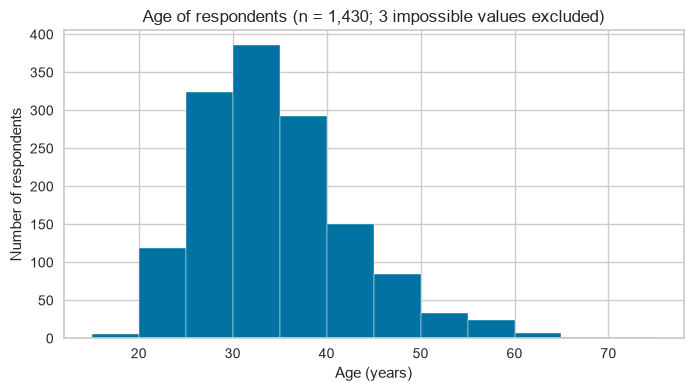

In [173]:
plausible = df["age"][(df["age"] >= 15) & (df["age"] <= 75)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(plausible, bins=range(15, 80, 5), edgecolor="white")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of respondents")
ax.set_title("Age of respondents (n = 1,430; 3 impossible values excluded)")
plt.show()

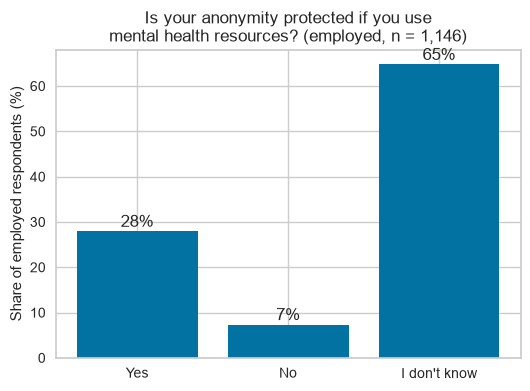

In [174]:
order = ["Yes", "No", "I don't know"]
shares = df["cur_anonymity_protected"].value_counts(normalize=True).reindex(order) * 100

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(shares.index, shares.values)
ax.set_ylabel("Share of employed respondents (%)")
ax.set_title("Is your anonymity protected if you use\nmental health resources? (employed, n = 1,146)")
for i, v in enumerate(shares.values):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center")
plt.show()

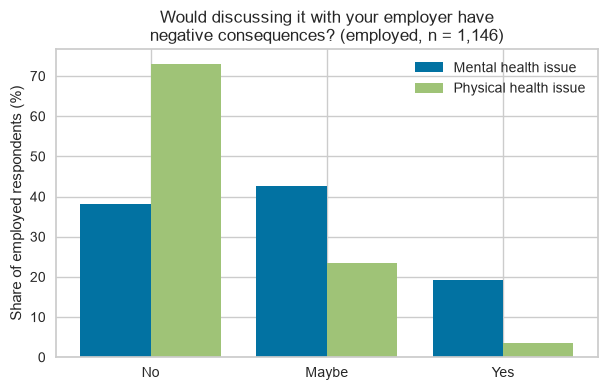

In [175]:
order = ["No", "Maybe", "Yes"]
mh = df["cur_mh_disclosure_conseq"].value_counts(normalize=True).reindex(order) * 100
ph = df["cur_ph_disclosure_conseq"].value_counts(normalize=True).reindex(order) * 100

x = range(len(order))
width = 0.4

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([i - width / 2 for i in x], mh.values, width, label="Mental health issue")
ax.bar([i + width / 2 for i in x], ph.values, width, label="Physical health issue")
ax.set_xticks(list(x))
ax.set_xticklabels(order)
ax.set_ylabel("Share of employed respondents (%)")
ax.set_title("Would discussing it with your employer have\nnegative consequences? (employed, n = 1,146)")
ax.legend()
plt.show()

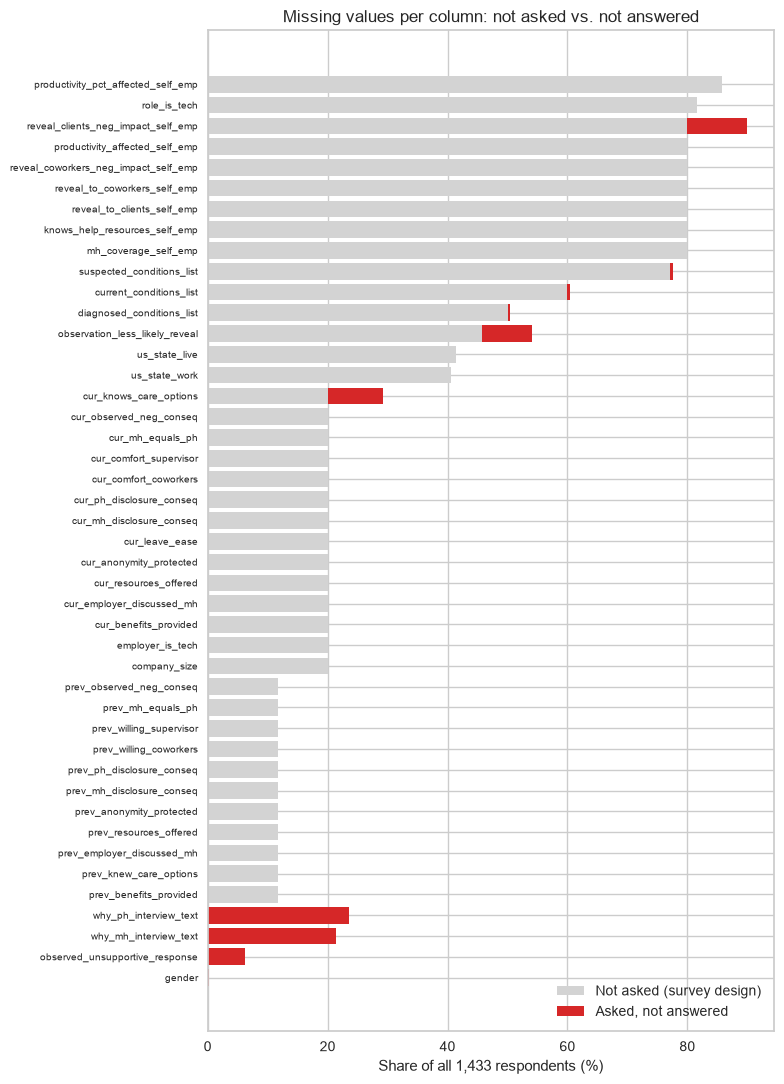

In [176]:
gaps = split[(split["not_asked"] + split["non_response"]) > 0].copy()
gaps["not_asked_pct"] = gaps["not_asked"] / len(df) * 100
gaps["non_response_pct_all"] = gaps["non_response"] / len(df) * 100
gaps = gaps.sort_values(["not_asked_pct", "non_response_pct_all"])

fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(gaps["column"], gaps["not_asked_pct"],
        color="lightgray", label="Not asked (survey design)")
ax.barh(gaps["column"], gaps["non_response_pct_all"], left=gaps["not_asked_pct"],
        color="tab:red", label="Asked, not answered")
ax.set_xlabel("Share of all 1,433 respondents (%)")
ax.set_title("Missing values per column: not asked vs. not answered")
ax.legend(loc="lower right")
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

In [177]:
print(pd.crosstab(df["mh_disorder_current"], df["diagnosed_by_professional"]))
print()
print(pd.crosstab(df["mh_disorder_past"], df["mh_disorder_current"]))
print()
print(pd.crosstab(df["diagnosed_by_professional"], df["sought_treatment"]))

diagnosed_by_professional   No  Yes
mh_disorder_current                
Maybe                      203  124
No                         450   81
Yes                         64  511

mh_disorder_current  Maybe   No  Yes
mh_disorder_past                    
Maybe                  155   65   26
No                      50  371   30
Yes                    122   95  519

sought_treatment             0    1
diagnosed_by_professional          
No                         554  163
Yes                         40  676


In [178]:
order = ["Yes", "No", "I don't know"]

counts = pd.crosstab(df["cur_resources_offered"], df["cur_anonymity_protected"])
print(counts.reindex(index=order, columns=order))
print()

shares = pd.crosstab(df["cur_resources_offered"], df["cur_anonymity_protected"], normalize="index") * 100
print(shares.reindex(index=order, columns=order).round(0))

cur_anonymity_protected  Yes  No  I don't know
cur_resources_offered                         
Yes                      158  10           127
No                        98  60           373
I don't know              64  14           242

cur_anonymity_protected   Yes    No  I don't know
cur_resources_offered                            
Yes                      54.0   3.0          43.0
No                       18.0  11.0          70.0
I don't know             20.0   4.0          76.0


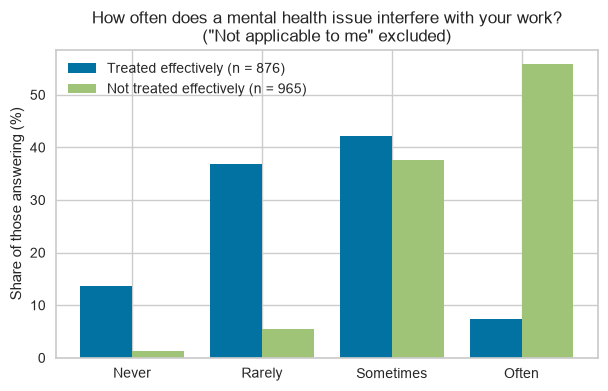

In [179]:
order = ["Never", "Rarely", "Sometimes", "Often"]
na = "Not applicable to me"

treated = df["interferes_when_treated"]
untreated = df["interferes_when_not_treated"]

t = treated[treated != na].value_counts(normalize=True).reindex(order) * 100
u = untreated[untreated != na].value_counts(normalize=True).reindex(order) * 100

x = range(len(order))
width = 0.4

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([i - width / 2 for i in x], t.values, width,
       label=f"Treated effectively (n = {(treated != na).sum()})")
ax.bar([i + width / 2 for i in x], u.values, width,
       label=f"Not treated effectively (n = {(untreated != na).sum()})")
ax.set_xticks(list(x))
ax.set_xticklabels(order)
ax.set_ylabel("Share of those answering (%)")
ax.set_title("How often does a mental health issue interfere with your work?\n(\"Not applicable to me\" excluded)")
ax.legend()
plt.show()

In [180]:
order_mh = ["Yes", "Maybe", "No"]
employed = df[df["self_employed"] == 0]

print(employed["mh_disorder_current"].value_counts().reindex(order_mh))
print()

order_res = ["Yes", "No", "I don't know"]
res = pd.crosstab(employed["mh_disorder_current"], employed["cur_resources_offered"], normalize="index") * 100
print(res.reindex(index=order_mh, columns=order_res).round(0))
print()

order_ben = ["Yes", "No", "I don't know", "Not eligible for coverage / N/A"]
ben = pd.crosstab(employed["mh_disorder_current"], employed["cur_benefits_provided"], normalize="index") * 100
print(ben.reindex(index=order_mh, columns=order_ben).round(0))

mh_disorder_current
Yes      451
Maybe    254
No       441
Name: count, dtype: int64

cur_resources_offered   Yes    No  I don't know
mh_disorder_current                            
Yes                    29.0  46.0          25.0
Maybe                  22.0  49.0          29.0
No                     24.0  45.0          31.0

cur_benefits_provided   Yes    No  I don't know  \
mh_disorder_current                               
Yes                    57.0  17.0          19.0   
Maybe                  41.0  15.0          35.0   
No                     38.0  22.0          33.0   

cur_benefits_provided  Not eligible for coverage / N/A  
mh_disorder_current                                     
Yes                                                7.0  
Maybe                                              9.0  
No                                                 7.0  


In [181]:
print(df["self_employed"].value_counts(normalize=True).mul(100).round(0))
print()

size_order = ["1-5", "6-25", "26-100", "100-500", "500-1000", "More than 1000"]
print(df["company_size"].value_counts(normalize=True).reindex(size_order).mul(100).round(0))
print()

print(df["works_remotely"].value_counts(normalize=True).mul(100).round(0))
print()

print(df["country_work"].value_counts(normalize=True).head(5).mul(100).round(0))

self_employed
0    80.0
1    20.0
Name: proportion, dtype: float64

company_size
1-5                5.0
6-25              18.0
26-100            25.0
100-500           22.0
500-1000           7.0
More than 1000    22.0
Name: proportion, dtype: float64

works_remotely
Sometimes    53.0
Always       24.0
Never        23.0
Name: proportion, dtype: float64

country_work
United States of America    59.0
United Kingdom              13.0
Canada                       5.0
Germany                      4.0
Netherlands                  3.0
Name: proportion, dtype: float64


In [182]:
column_map["decision"] = "keep"
column_map.loc[column_map["short_name"].str.endswith("_text"), "decision"] = "drop"

print(column_map["decision"].value_counts())

decision
keep    61
drop     2
Name: count, dtype: int64


In [183]:
names = column_map["short_name"]

# default for everything not covered below
column_map["reason"] = "full feature scope (Phase 5)"

# rules for whole blocks, recognised by prefix or suffix
column_map.loc[names.str.startswith("cur_"), "reason"] = "current employer; 'not asked' for the self-employed (Phase 5)"
column_map.loc[names.str.startswith("prev_"), "reason"] = "previous employers only; 'no previous employer' for the 169 (Phase 5)"
column_map.loc[names.str.endswith("_self_emp"), "reason"] = "self-employed only; kept with 'not asked' (Phase 5)"
column_map.loc[names.str.endswith("_list"), "reason"] = "split into one yes/no column per condition (Phase 5)"
column_map.loc[names.str.endswith("_text"), "reason"] = "free text; would need text analysis (omission)"

# rules for single columns
reason_overrides = {
    "self_employed": "full scope; repeats the 'not asked' indicators of the self-employed block (Phase 6, step 40)",
    "has_prev_employers": "full scope; repeats the 'no previous employer' indicators (Phase 6, step 40)",
    "company_size": "employer size; 'not asked' for the self-employed (Phase 5)",
    "employer_is_tech": "kept, not merged with role_is_tech; 'not asked' for the self-employed (Phase 5)",
    "role_is_tech": "non-tech employers only; kept with 'not asked', not merged (Phase 5)",
    "mh_disorder_past": "health question, kept unchanged (Phase 5)",
    "mh_disorder_current": "health question, kept unchanged (Phase 5)",
    "diagnosed_by_professional": "health question, kept unchanged (Phase 5)",
    "sought_treatment": "health question, kept unchanged (Phase 5)",
    "family_history_mh": "full scope; health-related, but not one of the four health questions",
    "reveal_clients_neg_impact_self_emp": "kept (Phase 5); weakest column: 143 of 287 unanswered, perceived impact",
    "country_live": "kept (Phase 5); near-duplicate of country_work",
    "country_work": "kept (Phase 5); near-duplicate of country_live",
    "us_state_live": "kept (Phase 5); 'not asked' outside the US",
    "us_state_work": "kept (Phase 5); 'not asked' outside the US",
    "age": "kept; impossible values set to missing in Phase 6",
    "gender": "kept; cleaning in Phase 6",
    "work_position": "kept; split into one yes/no column per role in Phase 6",
}

print(set(reason_overrides) - set(names))

for name, reason in reason_overrides.items():
    column_map.loc[names == name, "reason"] = reason

set()


In [184]:
print((column_map["reason"] == "full feature scope (Phase 5)").sum())
print(column_map.shape)

column_map.to_csv("data/column_map.csv", index=False)

10
(63, 8)


In [185]:
drop_cols = column_map.loc[column_map["decision"] == "drop", "short_name"].tolist()
print(drop_cols)

df_clean = df.drop(columns=drop_cols)
print(df.shape, df_clean.shape)

['why_ph_interview_text', 'why_mh_interview_text']
(1433, 63) (1433, 61)


In [186]:
top_share = {}
for col in df_clean.columns:
    shares = df_clean[col].value_counts(dropna=False, normalize=True)
    top_share[col] = shares.iloc[0]

top_share = pd.Series(top_share).sort_values(ascending=False)
print(top_share.head(10).round(3))

reveal_clients_neg_impact_self_emp    0.900
has_prev_employers                    0.882
productivity_pct_affected_self_emp    0.858
role_is_tech                          0.816
self_employed                         0.800
reveal_to_clients_self_emp            0.800
knows_help_resources_self_emp         0.800
productivity_affected_self_emp        0.800
reveal_to_coworkers_self_emp          0.800
mh_coverage_self_emp                  0.800
dtype: float64


In [187]:
def map_gender(answer):
    if pd.isna(answer):
        return answer
    text = answer.strip().lower()
    if text == "f" or "female" in text or "woman" in text:
        return "female"
    if text == "m" or "male" in text or text == "man" or text.startswith("man ") or " man" in text:
        return "male"
    return "other"

df_clean["gender"] = df_clean["gender"].apply(map_gender)

print(df_clean["gender"].value_counts(dropna=False))

check = pd.DataFrame({"original": df["gender"], "mapped": df_clean["gender"]})
print(check.groupby("mapped")["original"].nunique())

gender
male      1054
female     342
other       34
NaN          3
Name: count, dtype: int64
mapped
female    22
male      19
other     29
Name: original, dtype: int64


In [188]:
list_cols = ["current_conditions_list", "suspected_conditions_list", "diagnosed_conditions_list"]

for col in list_cols:
    items = df_clean[col].dropna().str.split("|").explode().str.strip()
    counts = items.value_counts()
    print(col, "| items:", len(counts),
          "| used by fewer than 5:", (counts < 5).sum(),
          "| fewer than 10:", (counts < 10).sum(),
          "| largest:", counts.iloc[0])

current_conditions_list | items: 33 | used by fewer than 5: 21 | fewer than 10: 22 | largest: 412
suspected_conditions_list | items: 23 | used by fewer than 5: 11 | fewer than 10: 13 | largest: 219
diagnosed_conditions_list | items: 34 | used by fewer than 5: 22 | fewer than 10: 23 | largest: 526


In [189]:
list_cols = ["current_conditions_list", "suspected_conditions_list", "diagnosed_conditions_list"]
prefixes = {"current_conditions_list": "cur_cond__",
            "suspected_conditions_list": "sus_cond__",
            "diagnosed_conditions_list": "diag_cond__"}
min_count = 10

new_blocks = []
for col in list_cols:
    dummies = df_clean[col].str.get_dummies(sep="|")
    counts = dummies.sum()
    frequent = counts[counts >= min_count].index
    rare = counts[counts < min_count].index

    block = dummies[frequent].copy()
    block["other_condition"] = (dummies[rare].sum(axis=1) > 0).astype(int)
    block = block.add_prefix(prefixes[col])

    block = block.astype(float)
    block.loc[df_clean[col].isna()] = float("nan")

    print(col, "| items:", dummies.shape[1], "| frequent:", len(frequent),
          "| rare grouped:", len(rare), "| new columns:", block.shape[1],
          "| other_condition = 1:", int(block[prefixes[col] + "other_condition"].sum()))
    new_blocks.append(block)

df_clean = df_clean.drop(columns=list_cols)
df_clean = pd.concat([df_clean] + new_blocks, axis=1)
print(df_clean.shape)

current_conditions_list | items: 33 | frequent: 11 | rare grouped: 22 | new columns: 12 | other_condition = 1: 28
suspected_conditions_list | items: 23 | frequent: 10 | rare grouped: 13 | new columns: 11 | other_condition = 1: 23
diagnosed_conditions_list | items: 34 | frequent: 11 | rare grouped: 23 | new columns: 12 | other_condition = 1: 32
(1433, 93)


In [190]:
roles = df_clean["work_position"].str.get_dummies(sep="|")
role_counts = roles.sum()
print("roles:", roles.shape[1], "| fewer than 10:", (role_counts < 10).sum(), "| smallest:", role_counts.min())

roles = roles.add_prefix("role__")
df_clean = df_clean.drop(columns=["work_position"])
df_clean = pd.concat([df_clean, roles], axis=1)
print(df_clean.shape)

print(roles.sum(axis=1).value_counts().sort_index())

roles: 12 | fewer than 10: 0 | smallest: 12
(1433, 104)
1     817
2     281
3     159
4     106
5      33
6      22
7       9
8       3
9       2
10      1
Name: count, dtype: int64


In [191]:
df_clean["age"] = df_clean["age"].astype(float)
is_impossible = df_clean["age"].isin([3, 99, 323])
print("impossible ages set to missing:", is_impossible.sum())
df_clean.loc[is_impossible, "age"] = float("nan")

df_clean["age_group"] = pd.cut(df_clean["age"],
                               bins=[0, 24, 34, 44, 120],
                               labels=["under 25", "25-34", "35-44", "45 and over"])
df_clean = df_clean.drop(columns=["age"])

print(df_clean["age_group"].value_counts(dropna=False, sort=False))
print(df_clean.shape)

impossible ages set to missing: 3
age_group
under 25       125
25-34          710
35-44          442
45 and over    153
NaN              3
Name: count, dtype: int64
(1433, 104)


In [192]:
rule_of = dict(zip(column_map["short_name"], column_map["asked_of"]))
rule_of["age_group"] = "all"

block_prefixes = ("cur_cond__", "sus_cond__", "diag_cond__", "role__")
filled = []
for col in df_clean.columns:
    if col.startswith(block_prefixes) or df_clean[col].notna().all():
        continue
    asked = asked_mask[rule_of[col]]
    missing = df_clean[col].isna()
    df_clean[col] = df_clean[col].astype(object)
    df_clean.loc[missing & ~asked, col] = "not asked"
    df_clean.loc[missing & asked, col] = "no answer"
    filled.append(col)

print("columns filled:", len(filled))
print("'not asked' cells:", df_clean.isin(["not asked"]).sum().sum())
print("'no answer' cells:", df_clean.isin(["no answer"]).sum().sum())

columns filled: 40
'not asked' cells: 18129
'no answer' cells: 491


In [193]:
list_rules = {"cur_cond__": rule_of["current_conditions_list"],
              "sus_cond__": rule_of["suspected_conditions_list"],
              "diag_cond__": rule_of["diagnosed_conditions_list"]}

for prefix, rule in list_rules.items():
    if prefix + "not_asked" in df_clean.columns:
        continue
    block_cols = [c for c in df_clean.columns if c.startswith(prefix)]
    asked = asked_mask[rule]
    missing = df_clean[block_cols[0]].isna()
    df_clean[prefix + "not_asked"] = (missing & ~asked).astype(int)
    df_clean[prefix + "no_answer"] = (missing & asked).astype(int)
    df_clean[block_cols] = df_clean[block_cols].fillna(0)
    print(prefix, "| not asked:", df_clean[prefix + "not_asked"].sum(),
          "| no answer:", df_clean[prefix + "no_answer"].sum())

print("empty cells left:", df_clean.isna().sum().sum())
print(df_clean.shape)

cur_cond__ | not asked: 858 | no answer: 7
sus_cond__ | not asked: 1106 | no answer: 5
diag_cond__ | not asked: 717 | no answer: 5
empty cells left: 0
(1433, 110)


In [194]:
rest_of_europe = [
    "Albania", "Austria", "Belarus", "Belgium", "Bosnia and Herzegovina", "Bulgaria",
    "Croatia", "Cyprus", "Czech Republic", "Denmark", "Estonia", "Finland", "France",
    "Germany", "Greece", "Hungary", "Iceland", "Ireland", "Italy", "Latvia", "Lithuania",
    "Luxembourg", "Macedonia", "Malta", "Moldova", "Netherlands", "Norway", "Poland",
    "Portugal", "Romania", "Russia", "Serbia", "Slovakia", "Slovenia", "Spain", "Sweden",
    "Switzerland", "Ukraine",
]

def to_region(country):
    if country == "United States of America":
        return "US"
    if country == "Canada":
        return "Canada"
    if country == "United Kingdom":
        return "UK"
    if country in rest_of_europe:
        return "rest of Europe"
    return "rest of world"

for col in ["country_live", "country_work"]:
    df_clean[col] = df[col].apply(to_region)
    print(df_clean[col].value_counts())

print(sorted(df.loc[df_clean["country_live"] == "rest of world", "country_live"].unique()))
print(sorted(df.loc[df_clean["country_work"] == "rest of world", "country_work"].unique()))

df_clean = df_clean.drop(columns=["us_state_live", "us_state_work"], errors="ignore")
print(df_clean.shape)

country_live
US                840
rest of Europe    238
UK                180
rest of world      97
Canada             78
Name: count, dtype: int64
country_work
US                851
rest of Europe    231
UK                183
rest of world      94
Canada             74
Name: count, dtype: int64
['Afghanistan', 'Algeria', 'Argentina', 'Australia', 'Bangladesh', 'Brazil', 'Brunei', 'Chile', 'China', 'Colombia', 'Costa Rica', 'Ecuador', 'Guatemala', 'India', 'Iran', 'Israel', 'Japan', 'Mexico', 'New Zealand', 'Other', 'Pakistan', 'South Africa', 'Taiwan', 'Venezuela', 'Vietnam']
['Afghanistan', 'Argentina', 'Australia', 'Bangladesh', 'Brazil', 'Brunei', 'Chile', 'China', 'Colombia', 'Costa Rica', 'Ecuador', 'Guatemala', 'India', 'Iran', 'Israel', 'Japan', 'Mexico', 'New Zealand', 'Other', 'Pakistan', 'South Africa', 'Turkey', 'United Arab Emirates', 'Venezuela', 'Vietnam']
(1433, 108)


In [195]:
to_encode = [c for c in df_clean.columns if not pd.api.types.is_numeric_dtype(df_clean[c])]
print("columns to one-hot encode:", len(to_encode))
print(df_clean[to_encode].nunique().sort_values(ascending=False).head(10))

df_encoded = pd.get_dummies(df_clean, columns=to_encode, dtype=int).astype(float)

print(df_encoded.shape)
print("empty cells:", df_encoded.isna().sum().sum())
print("values used:", sorted(pd.unique(df_encoded.values.ravel())))

columns to one-hot encode: 52
company_size                          7
cur_leave_ease                        7
reveal_to_coworkers_self_emp          6
reveal_to_clients_self_emp            6
willing_share_friends_family          6
reveal_clients_neg_impact_self_emp    5
cur_benefits_provided                 5
cur_knows_care_options                5
observation_less_likely_reveal        5
country_work                          5
dtype: int64
(1433, 286)
empty cells: 0
values used: [np.float64(0.0), np.float64(1.0)]


In [196]:
X = df_encoded.copy()

share_of_ones = X.mean()
spread = X.var()

print("columns:", X.shape[1])
print("columns where fewer than 1% have a 1:", (share_of_ones < 0.01).sum())
print("columns where fewer than 5% have a 1:", (share_of_ones < 0.05).sum())
print("spread: smallest", round(spread.min(), 4), "| largest", round(spread.max(), 4))

columns: 286
columns where fewer than 1% have a 1: 14
columns where fewer than 5% have a 1: 66
spread: smallest 0.0014 | largest 0.2502


In [197]:
scores = pd.DataFrame(index=df_clean.index)

# Score A: known support at the current employer (employed only, profiles only)
support_cols = ["cur_benefits_provided", "cur_resources_offered",
                "cur_employer_discussed_mh", "cur_anonymity_protected"]
for col in support_cols:
    print(col, "| Yes:", (df_clean[col] == "Yes").sum())

employed = df_clean["self_employed"] == 0
scores["support_score"] = (df_clean[support_cols] == "Yes").mean(axis=1)
scores.loc[~employed, "support_score"] = float("nan")

# Score B: perceived stigma (everyone, goes into X)
def stigma_level(answer):
    if answer == "Maybe":
        return 0.5
    if answer.startswith("Yes"):
        return 0.75 if "think" in answer else 1.0
    if answer.startswith("No"):
        return 0.25 if "think" in answer else 0.0
    return None

career = df_clean["career_hurt_if_identified"].apply(stigma_level).astype(float)
coworkers = df_clean["coworkers_view_negatively"].apply(stigma_level).astype(float)
interview = df_clean["would_raise_mh_interview"].map({"Yes": 0.0, "Maybe": 0.5, "No": 1.0})

print("answers not placed:", career.isna().sum(), coworkers.isna().sum(), interview.isna().sum())

scores["stigma_score"] = (career + coworkers + interview) / 3
X["stigma_score"] = scores["stigma_score"]

print(scores.describe().round(2))
print(X.shape)

cur_benefits_provided | Yes: 531
cur_resources_offered | Yes: 295
cur_employer_discussed_mh | Yes: 230
cur_anonymity_protected | Yes: 320
answers not placed: 0 0 0
       support_score  stigma_score
count        1146.00       1433.00
mean            0.30          0.62
std             0.31          0.19
min             0.00          0.00
25%             0.00          0.50
50%             0.25          0.67
75%             0.50          0.83
max             1.00          1.00
(1433, 287)


In [198]:
dup_mask = X.T.duplicated()
print("exact duplicate columns:", dup_mask.sum())

corr = X.corr().abs()
values = corr.values
cols = list(X.columns)
pairs = []
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        pairs.append((cols[i], cols[j], values[i, j]))
pairs = pd.DataFrame(pairs, columns=["col_a", "col_b", "abs_r"])

print("pairs with |r| = 1:", (pairs["abs_r"] > 0.9999).sum())
print("pairs with |r| >= 0.95:", (pairs["abs_r"] >= 0.95).sum())
print("pairs with |r| >= 0.9:", (pairs["abs_r"] >= 0.9).sum())
print(pairs[pairs["abs_r"] >= 0.95].sort_values("abs_r", ascending=False).head(20))

exact duplicate columns: 31
pairs with |r| = 1: 304
pairs with |r| >= 0.95: 310
pairs with |r| >= 0.9: 313
                                      col_a  \
37804           prev_mh_equals_ph_not asked   
35707    prev_anonymity_protected_not asked   
35702    prev_anonymity_protected_not asked   
35697    prev_anonymity_protected_not asked   
35693    prev_anonymity_protected_not asked   
35689    prev_anonymity_protected_not asked   
35186      prev_resources_offered_not asked   
35182      prev_resources_offered_not asked   
35177      prev_resources_offered_not asked   
35172      prev_resources_offered_not asked   
35168      prev_resources_offered_not asked   
35164      prev_resources_offered_not asked   
35159      prev_resources_offered_not asked   
34748  prev_employer_discussed_mh_not asked   
34744  prev_employer_discussed_mh_not asked   
34739  prev_employer_discussed_mh_not asked   
34734  prev_employer_discussed_mh_not asked   
34730  prev_employer_discussed_mh_not asked   


In [199]:
print(pairs[(pairs["abs_r"] >= 0.9) & (pairs["abs_r"] <= 0.9999)].sort_values("abs_r", ascending=False))

                                                 col_a  \
40892                                  country_live_UK   
40925                      country_live_rest of Europe   
40909                                  country_live_US   
16951                                 role_is_tech_1.0   
16068                             employer_is_tech_0.0   
40874                              country_live_Canada   
40940                       country_live_rest of world   
40788                                    gender_female   
28805  reveal_to_clients_self_emp_Not applicable to me   

                                                   col_b     abs_r  
40892                                    country_work_UK  0.977964  
40925                        country_work_rest of Europe  0.977212  
40909                                    country_work_US  0.975603  
16951                             role_is_tech_not asked  0.964899  
16068                                   role_is_tech_1.0  0.964899  
40874

In [200]:
not_asked_like = ("_not asked", "_not_asked", "_no answer", "_no_answer")

ordered = [c for c in X.columns if not c.endswith(not_asked_like)] + \
          [c for c in X.columns if c.endswith(not_asked_like)]

values = X[ordered].corr().abs().values

drop = []
for i, col in enumerate(ordered):
    if col in drop:
        continue
    for j in range(i + 1, len(ordered)):
        if values[i, j] > 0.9999 and ordered[j] not in drop:
            drop.append(ordered[j])

print("columns dropped:", len(drop))
X = X.drop(columns=drop)
print(X.shape)

check = X.corr().abs().values
n = check.shape[0]
print("pairs with |r| = 1 left:", sum(check[i, j] > 0.9999 for i in range(n) for j in range(i + 1, n)))

columns dropped: 38
(1433, 249)
pairs with |r| = 1 left: 0


In [201]:
print(X.shape)
print("empty cells:", X.isna().sum().sum())
print("column types:", X.dtypes.unique())

(1433, 249)
empty cells: 0
column types: [dtype('float64')]


In [202]:
import numpy as np
from sklearn.decomposition import PCA

pca_full = PCA(random_state=42)
pca_full.fit(X)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

print("Number of components:", pca_full.n_components_)
print("First 10 components:", explained[:10].round(3))
print("First 2 together:", cumulative[1].round(3))

for threshold in [0.5, 0.7, 0.8, 0.9]:
    n = (cumulative < threshold).sum() + 1
    print("Components needed for", threshold, ":", n)

Number of components: 249
First 10 components: [0.077 0.059 0.046 0.034 0.028 0.025 0.024 0.02  0.018 0.017]
First 2 together: 0.136
Components needed for 0.5 : 22
Components needed for 0.7 : 47
Components needed for 0.8 : 65
Components needed for 0.9 : 94


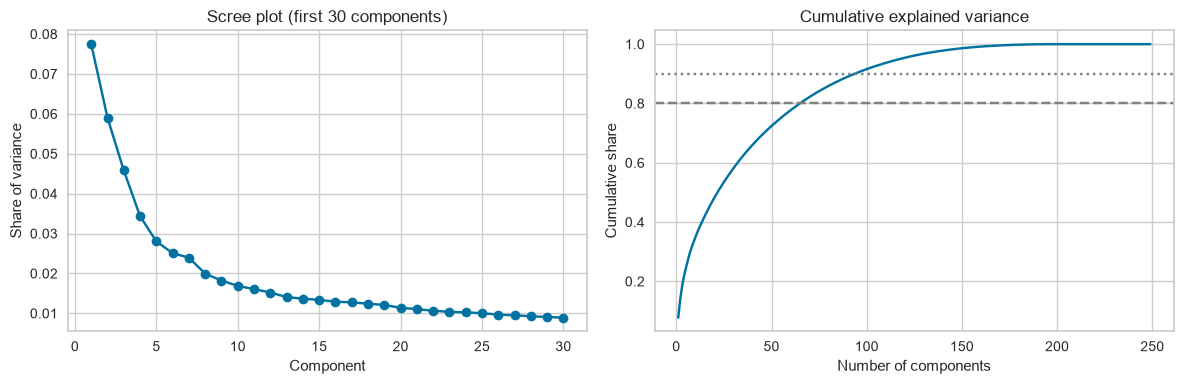

In [203]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(1, 31), explained[:30], marker="o")
axes[0].set_xlabel("Component")
axes[0].set_ylabel("Share of variance")
axes[0].set_title("Scree plot (first 30 components)")

axes[1].plot(range(1, len(cumulative) + 1), cumulative)
axes[1].axhline(0.8, color="grey", linestyle="--")
axes[1].axhline(0.9, color="grey", linestyle=":")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative share")
axes[1].set_title("Cumulative explained variance")

plt.tight_layout()
plt.show()

In [204]:
n_elbow = 4
n_70 = (cumulative < 0.7).sum() + 1
print("Candidates for Phase 8:", n_elbow, "and", n_70)

Candidates for Phase 8: 4 and 47


In [205]:
import pandas as pd

weights = pd.DataFrame(
    pca_full.components_[:5].T,
    index=X.columns,
    columns=["PC1", "PC2", "PC3", "PC4", "PC5"]
)

for pc in ["PC1", "PC2", "PC3", "PC4", "PC5"]:
    top = weights[pc].abs().sort_values(ascending=False).head(8).index
    print(pc)
    print(weights.loc[top, pc].round(2))
    print()

PC1
diagnosed_by_professional_No                                    0.26
mh_disorder_past_Yes                                           -0.25
sought_treatment                                               -0.24
interferes_when_treated_Not applicable to me                    0.24
mh_disorder_current_Yes                                        -0.24
interferes_when_not_treated_Not applicable to me                0.23
diag_cond__Mood Disorder (Depression, Bipolar Disorder, etc)   -0.22
mh_disorder_current_No                                          0.22
Name: PC1, dtype: float64

PC2
self_employed                           0.28
cur_observed_neg_conseq_No             -0.27
cur_ph_disclosure_conseq_No            -0.24
employer_is_tech_1.0                   -0.24
cur_employer_discussed_mh_No           -0.21
productivity_affected_self_emp_Yes      0.20
cur_anonymity_protected_I don't know   -0.19
mh_coverage_self_emp_1.0                0.18
Name: PC2, dtype: float64

PC3
cur_comfort_coworkers_

In [206]:
pc_scores = pca_full.transform(X)

check = pd.DataFrame({
    "PC1": pc_scores[:, 0],
    "PC2": pc_scores[:, 1],
    "mh_disorder_current": df_clean["mh_disorder_current"].values,
    "self_employed": df_clean["self_employed"].values
})

print(check.groupby("mh_disorder_current")["PC1"].agg(["count", "mean"]).round(2))
print()
print(check.groupby("self_employed")["PC2"].agg(["count", "mean"]).round(2))

                     count  mean
mh_disorder_current             
Maybe                  327  0.20
No                     531  1.36
Yes                    575 -1.37

               count  mean
self_employed             
0               1146 -0.62
1                287  2.48


In [207]:
weights = pd.DataFrame(
    pca_full.components_[:7].T,
    index=X.columns,
    columns=["PC1", "PC2", "PC3", "PC4", "PC5", "PC6", "PC7"]
)

for pc in ["PC6", "PC7"]:
    top = weights[pc].abs().sort_values(ascending=False).head(8).index
    print(pc)
    print(weights.loc[top, pc].round(2))
    print()

PC6
observation_less_likely_reveal_not asked    0.23
prev_ph_disclosure_conseq_Some of them     -0.20
prev_observed_neg_conseq_Some of them      -0.20
prev_mh_equals_ph_None did                 -0.20
prev_employer_discussed_mh_None did        -0.20
observed_unsupportive_response_No           0.20
prev_resources_offered_None did            -0.19
has_prev_employers                         -0.18
Name: PC6, dtype: float64

PC7
country_live_US                             0.35
country_work_US                             0.35
prev_observed_neg_conseq_None of them       0.28
prev_anonymity_protected_I don't know       0.21
observation_less_likely_reveal_not asked    0.21
observed_unsupportive_response_No           0.20
prev_mh_equals_ph_I don't know              0.18
prev_observed_neg_conseq_Some of them      -0.17
Name: PC7, dtype: float64



In [208]:
pc1 = pd.Series(pc_scores[:, 0], index=X.index)
pc2 = pd.Series(pc_scores[:, 1], index=X.index)

corr = pd.DataFrame({
    "PC1": X.corrwith(pc1),
    "PC2": X.corrwith(pc2)
})
corr["length"] = (corr["PC1"] ** 2 + corr["PC2"] ** 2) ** 0.5

top = corr.sort_values("length", ascending=False).head(12)
print(top.round(2))

                                                     PC1   PC2  length
self_employed                                      -0.14  0.93    0.94
cur_observed_neg_conseq_No                          0.21 -0.82    0.85
diagnosed_by_professional_No                        0.80  0.12    0.81
productivity_affected_self_emp_Yes                 -0.25  0.76    0.80
mh_disorder_past_Yes                               -0.77 -0.11    0.78
interferes_when_treated_Not applicable to me        0.76  0.08    0.77
interferes_when_not_treated_Not applicable to me    0.76  0.06    0.76
sought_treatment                                   -0.76 -0.08    0.76
mh_disorder_current_Yes                            -0.74 -0.10    0.74
mh_coverage_self_emp_1.0                           -0.12  0.72    0.73
mh_disorder_past_No                                 0.71  0.03    0.71
diag_cond__Mood Disorder (Depression, Bipolar D... -0.69 -0.11    0.70


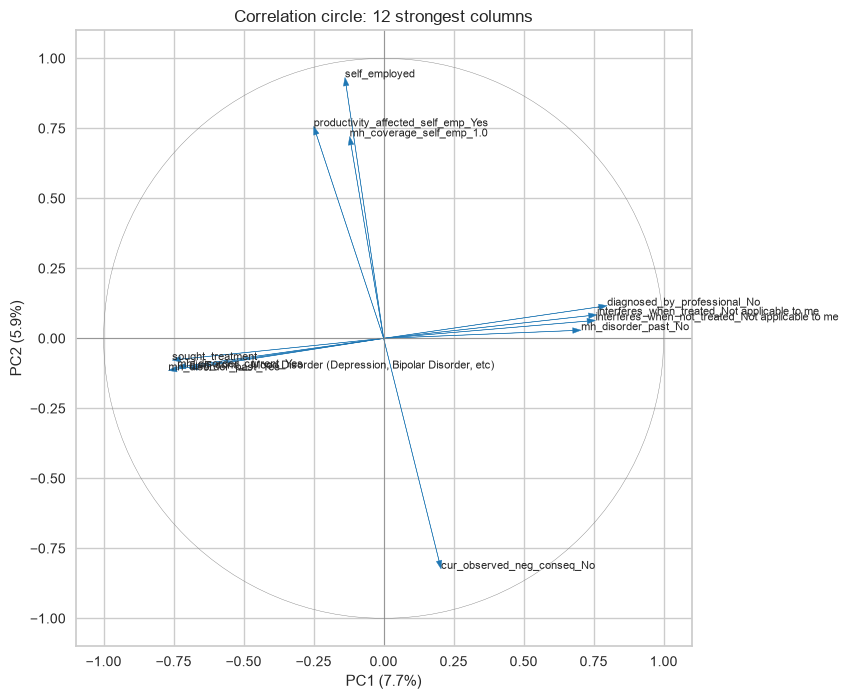

In [209]:
fig, ax = plt.subplots(figsize=(8, 8))

circle = plt.Circle((0, 0), 1, fill=False, color="grey")
ax.add_patch(circle)

for name, row in top.iterrows():
    ax.arrow(0, 0, row["PC1"], row["PC2"], head_width=0.02,
             length_includes_head=True, color="tab:blue")
    ax.text(row["PC1"], row["PC2"], name, fontsize=8)

ax.axhline(0, color="grey", linewidth=0.5)
ax.axvline(0, color="grey", linewidth=0.5)
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_aspect("equal")
ax.set_xlabel("PC1 (" + str(round(explained[0] * 100, 1)) + "%)")
ax.set_ylabel("PC2 (" + str(round(explained[1] * 100, 1)) + "%)")
ax.set_title("Correlation circle: 12 strongest columns")
plt.show()